In [15]:
# Primary VAR (VAR-SPY): Tables 3, 4 and 5, Figure 2, Tables B.1, B.3, C.1 and C.2, Figures D.1 and D.2
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.vector_ar.var_model import VAR

warnings.filterwarnings("ignore")
os.makedirs("output", exist_ok=True)

# Plot style for the thesis figures
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "mathtext.fontset": "dejavuserif", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "legend.frameon": False, "savefig.dpi": 300,
})
blue, orange, green, grey, red = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#8b1a1a"

In [16]:
# Merge the clean files into one monthly data set, December 2015 to December 2025 (121 months)
files = ["spy_clean.csv", "rsp_clean.csv", "voo_clean.csv", "vix_clean.csv", "dgs10_clean.csv",
         "AIStocks_ASVI8_Monthly.csv", "AIStocks_ASVI4_Monthly.csv",
         "mag7_clean.csv", "mag7b_clean.csv", "mag7c_clean.csv"]
df = pd.read_csv(files[0], parse_dates=["date"])
for f in files[1:]:
    df = df.merge(pd.read_csv(f, parse_dates=["date"]), on="date", how="inner")
df = df.sort_values("date").reset_index(drop=True)

# 2021-2025 subsample. December 2020 only serves as the first lag, so the VARs run on Jan 2021 to Dec 2025.
sub = df[df["date"] >= "2020-12-31"].reset_index(drop=True)
print(len(df), "months,", df["date"].min().date(), "to", df["date"].max().date())

labels = {"dlog_vix": "dlogVIX", "d_dgs10": "dDGS10", "ASVI8": "ASVI8", "ASVI4": "ASVI4",
          "flow_spy": "Flow SPY", "flow_rsp": "Flow RSP", "flow_voo": "Flow VOO",
          "mag7_ret": "Mag7 returns", "mag7b_ret": "Mag7B returns", "mag7c_ret": "Mag7C returns"}

# Cholesky order: VIX, yields, attention, ETF flow, Mag7 returns
cols = ["dlog_vix", "d_dgs10", "ASVI8", "flow_spy", "mag7_ret"]
samples = {"Full sample": df, "2021-2025": sub}

121 months, 2015-12-31 to 2025-12-31


In [17]:
def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

def granger(res, cause, effect):
    # F-test: do the lags of `cause` help predict `effect`?
    t = res.test_causality(effect, [cause], kind="f")
    return float(t.test_statistic), float(t.pvalue)


def fevd(res, response):
    # Share (%) of the forecast error variance of `response` explained by each shock, h = 1, 6, 12
    d = res.fevd(12).decomp[list(res.names).index(response)] * 100
    return pd.DataFrame({"h=1": d[0], "h=6": d[5], "h=12": d[11]}, index=list(res.names))


def irf_bands(res, impulse, response, h=12):
    # Orthogonalized impulse response with asymptotic 95% bands
    i, j = list(res.names).index(response), list(res.names).index(impulse)
    irf = res.irf(h)
    point = irf.orth_irfs[:, i, j]
    se = irf.stderr(orth=True)[:, i, j]
    return point, point - 1.959964 * se, point + 1.959964 * se


def largest_eigenvalue(res):
    # statsmodels reports the roots of the characteristic polynomial. The eigenvalues of the
    # companion matrix are their inverses, so the largest eigenvalue is 1 / smallest root.
    return 1 / np.abs(res.roots).min()

In [18]:
# Table B.1: lag selection, VAR(0) to VAR(4) on the same estimation sample. * marks the minimum.
rows = []
for name, data in samples.items():
    so = VAR(data[cols]).select_order(maxlags=4)
    best = so.selected_orders
    print(name, {k: int(v) for k, v in best.items()})
    for p in range(5):
        rows.append({"Sample": name, "Lag order": p,
                     "AIC": f"{so.ics['aic'][p]:.2f}" + ("*" if best["aic"] == p else ""),
                     "BIC": f"{so.ics['bic'][p]:.2f}" + ("*" if best["bic"] == p else ""),
                     "FPE (x 10^-9)": f"{so.ics['fpe'][p] * 1e9:.3f}" + ("*" if best["fpe"] == p else ""),
                     "HQIC": f"{so.ics['hqic'][p]:.2f}" + ("*" if best["hqic"] == p else "")})
tableB1 = pd.DataFrame(rows)
tableB1.to_csv("output/Table_B1_lag_selection.csv", index=False)
tableB1

Full sample {'aic': 2, 'bic': 1, 'hqic': 1, 'fpe': 2}
2021-2025 {'aic': 1, 'bic': 1, 'hqic': 1, 'fpe': 1}


,Sample,Lag order,AIC,BIC,FPE (x 10^-9),HQIC
0,Full sample,0,-19.77,-19.66,2.585,-19.73
1,Full sample,1,-20.65,-19.95*,1.072,-20.37*
2,Full sample,2,-20.67*,-19.37,1.056*,-20.14
3,Full sample,3,-20.49,-18.60,1.270,-19.73
4,Full sample,4,-20.36,-17.88,1.461,-19.36
5,2021-2025,0,-19.55,-19.37,3.229,-19.48
6,2021-2025,1,-20.61*,-19.54*,1.120*,-20.20*
7,2021-2025,2,-20.59,-18.62,1.167,-19.83
8,2021-2025,3,-20.43,-17.56,1.449,-19.32
9,2021-2025,4,-20.56,-16.80,1.411,-19.10


In [19]:
# VAR(1), lag chosen by BIC in both samples
res = {name: VAR(data[cols]).fit(1) for name, data in samples.items()}
for name, r in res.items():
    print(name)
    print(r.summary())

Full sample
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Tue, 13, Oct, 2026
Time:                     18:01:01
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -20.0111
Nobs:                     120.000    HQIC:                  -20.4250
Log likelihood:           421.118    FPE:                1.01579e-09
AIC:                     -20.7080    Det(Omega_mle):     7.95900e-10
--------------------------------------------------------------------
Results for equation dlog_vix
                 coefficient       std. error           t-stat            prob
------------------------------------------------------------------------------
const              -0.011007         0.022832           -0.482           0.630
L1.dlog_vix        -0.179885         0.104036           -1.729           0.084
L1.d_dgs10         -0.039471         0.085615        

In [20]:
# Stability and residual tests
for name, r in res.items():
    w = r.test_whiteness(nlags=10)
    n = r.test_normality()
    print(f"{name}: largest eigenvalue {largest_eigenvalue(r):.3f} (smallest root {np.abs(r.roots).min():.3f}), "
          f"Portmanteau Q {w.test_statistic:.1f} (critical value {w.crit_value:.1f}, p {w.pvalue:.3f}), "
          f"normality p {n.pvalue:.3f}")

Full sample: largest eigenvalue 0.793 (smallest root 1.261), Portmanteau Q 234.9 (critical value 261.0, p 0.312), normality p 0.000
2021-2025: largest eigenvalue 0.838 (smallest root 1.194), Portmanteau Q 221.0 (critical value 261.0, p 0.562), normality p 0.000


In [21]:
# Table 3: Mag7 returns equation
regressors = ["const"] + ["L1." + c for c in cols]
names = {"const": "Constant", **{"L1." + c: "L1." + labels[c] for c in cols}}
table3 = {}
for name, r in res.items():
    col = []
    for v in regressors:
        col += [f"{r.params.loc[v, 'mag7_ret']:.4f}{stars(r.pvalues.loc[v, 'mag7_ret'])}",
                f"({r.stderr.loc[v, 'mag7_ret']:.4f})"]
    col += [int(r.nobs), f"{r.llf:.1f}", f"{r.aic:.2f}", f"{r.bic:.2f}", "Yes" if r.is_stable() else "No",
            f"{r.test_whiteness(nlags=10).pvalue:.3f}"]
    table3[name] = col
index = [x for v in regressors for x in (names[v], "")] + [
    "Observations", "Log-likelihood (system)", "AIC (system)", "BIC (system)", "Stability", "Portmanteau p-value"]
table3 = pd.DataFrame(table3, index=index)
table3.to_csv("output/Table_3_VAR_SPY_Mag7_equation.csv")
table3

,Full sample,2021-2025
Constant,0.0198***,0.0084
,(0.0076),(0.0117)
L1.dlogVIX,-0.0352,0.0044
,(0.0344),(0.0519)
L1.dDGS10,-0.0148,-0.0075
,(0.0283),(0.0416)
L1.ASVI8,0.0274**,0.0378**
,(0.0128),(0.0161)
L1.Flow SPY,0.0078,-0.1822
,(0.2640),(0.4607)


In [22]:
# Table 4: Granger causality
tests = [("ASVI8", "mag7_ret", "ASVI8 does not cause Mag7 returns"),
         ("ASVI8", "flow_spy", "ASVI8 does not cause Flow SPY"),
         ("flow_spy", "mag7_ret", "Flow SPY does not cause Mag7 returns"),
         ("mag7_ret", "ASVI8", "Mag7 returns do not cause ASVI8"),
         ("dlog_vix", "mag7_ret", "dlogVIX does not cause Mag7 returns"),
         ("d_dgs10", "mag7_ret", "dDGS10 does not cause Mag7 returns")]
rows = []
for cause, effect, label in tests:
    row = {"Null hypothesis": label}
    for name, r in res.items():
        f, p = granger(r, cause, effect)
        row[f"F ({name})"] = f"{f:.3f}{stars(p)}"
        row[f"p ({name})"] = f"{p:.3f}"
    rows.append(row)
table4 = pd.DataFrame(rows)
table4.to_csv("output/Table_4_Granger_causality.csv", index=False)
table4

,Null hypothesis,F (Full sample),p (Full sample),F (2021-2025),p (2021-2025)
0,ASVI8 does not cause Mag7 returns,4.625**,0.032,5.500**,0.020
1,ASVI8 does not cause Flow SPY,1.577,0.210,0.776,0.379
2,Flow SPY does not cause Mag7 returns,0.001,0.976,0.156,0.693
3,Mag7 returns do not cause ASVI8,1.705,0.192,0.433,0.511
4,dlogVIX does not cause Mag7 returns,1.043,0.307,0.007,0.933
5,dDGS10 does not cause Mag7 returns,0.272,0.603,0.033,0.856


In [23]:
# Table 5: variance decomposition of Mag7 returns (%)
fevd_mag7 = {name: fevd(r, "mag7_ret") for name, r in res.items()}
table5 = pd.concat({name: f.rename(index=labels) for name, f in fevd_mag7.items()}, axis=1).round(1).astype(object)

# Last row: ASVI8 share divided by the Flow SPY share at h = 12
table5.loc["ASVI8 / Flow SPY"] = ""
for name, f in fevd_mag7.items():
    ratio = f.loc["ASVI8", "h=12"] / f.loc["flow_spy", "h=12"]
    table5.loc["ASVI8 / Flow SPY", (name, "h=12")] = f"{ratio:.0f}x" if ratio >= 20 else f"{ratio:.1f}x"
table5.to_csv("output/Table_5_FEVD_Mag7.csv")
table5

Full sample             2021-2025            
                         h=1   h=6  h=12       h=1   h=6  h=12
dlogVIX                 28.6  27.7  27.7      26.1  24.7  24.4
dDGS10                   2.4   2.4   2.4       6.6   6.0   5.9
ASVI8                    1.9   4.6   4.8       2.8   9.8  10.9
Flow SPY                 0.5   0.5   0.5       0.0   0.2   0.2
Mag7 returns            66.6  64.8  64.6      64.4  59.3  58.5
ASVI8 / Flow SPY                    9.9x                   47x

In [24]:
# Impulse responses (Section 4.6), one-standard-deviation shocks
for name, r in res.items():
    point, lower, upper = irf_bands(r, "ASVI8", "mag7_ret")
    shock = np.linalg.cholesky(r.sigma_u)[2, 2]                    # size of a one-SD ASVI8 shock
    print(f"{name}: one-SD ASVI8 shock = {shock:.2f}")
    print(f"  Mag7 response to ASVI8 (%): t=0 {point[0] * 100:.2f}, t=1 {point[1] * 100:.2f}, "
          f"sum t=1 to 12 {point[1:].sum() * 100:.1f}, band excludes zero at t =",
          np.where((lower > 0) | (upper < 0))[0].tolist())
    point, lower, upper = irf_bands(r, "dlog_vix", "mag7_ret")
    print(f"  Mag7 response to dlogVIX (%): t=0 {point[0] * 100:.2f}, band excludes zero at t =",
          np.where((lower > 0) | (upper < 0))[0].tolist())

growth = res["2021-2025"].params.loc["L1.ASVI8", "mag7_ret"] / res["Full sample"].params.loc["L1.ASVI8", "mag7_ret"] - 1
print(f"\nASVI8 coefficient in 2021-2025 vs full sample: {growth:+.0%}")

Full sample: one-SD ASVI8 shock = 0.34
  Mag7 response to ASVI8 (%): t=0 1.01, t=1 0.80, sum t=1 to 12 3.7, band excludes zero at t = [2]
  Mag7 response to dlogVIX (%): t=0 -3.95, band excludes zero at t = [0]
2021-2025: one-SD ASVI8 shock = 0.38
  Mag7 response to ASVI8 (%): t=0 1.31, t=1 1.37, sum t=1 to 12 7.1, band excludes zero at t = [1, 2, 3]
  Mag7 response to dlogVIX (%): t=0 -3.97, band excludes zero at t = [0]

ASVI8 coefficient in 2021-2025 vs full sample: +38%


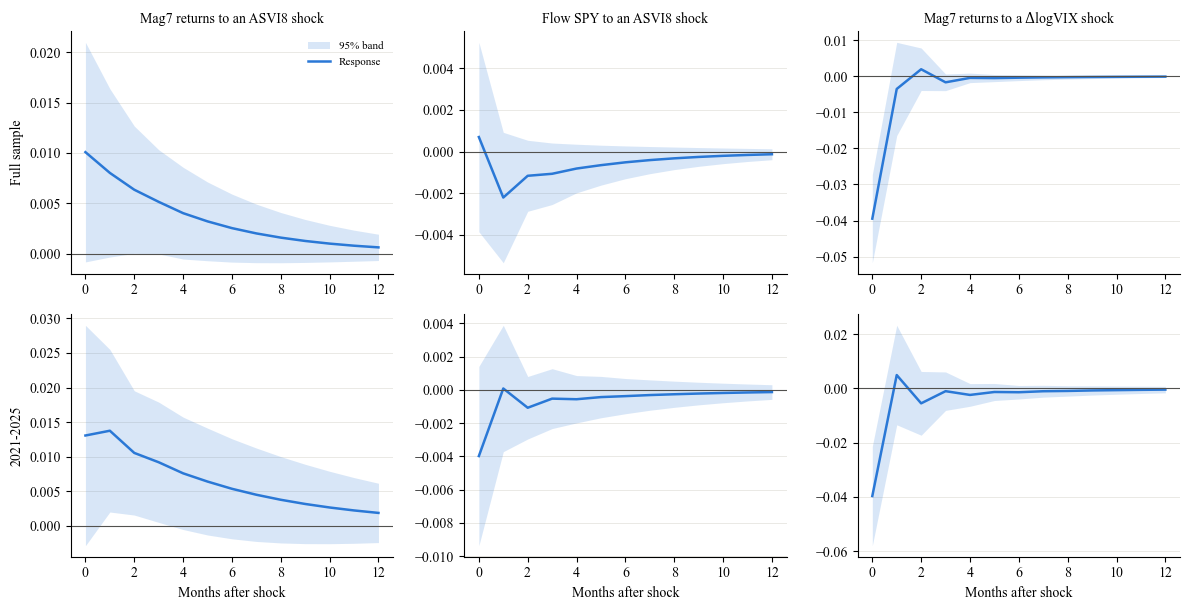

In [25]:
# Figure 2: the three responses discussed in Sections 4.6.1 to 4.6.3 (top: full sample, bottom: 2021-2025)
panels = [("ASVI8", "mag7_ret", "Mag7 returns to an ASVI8 shock"),
          ("ASVI8", "flow_spy", "Flow SPY to an ASVI8 shock"),
          ("dlog_vix", "mag7_ret", r"Mag7 returns to a $\Delta$logVIX shock")]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for row, (name, r) in enumerate(res.items()):
    for col, (impulse, response, title) in enumerate(panels):
        ax = axes[row, col]
        point, lower, upper = irf_bands(r, impulse, response)
        ax.fill_between(range(13), lower, upper, color=blue, alpha=0.18, lw=0, label="95% band")
        ax.plot(range(13), point, color=blue, lw=1.8, label="Response")
        ax.axhline(0, color=grey, lw=0.8)
        ax.set_xticks(range(0, 13, 2))
        if row == 0:
            ax.set_title(title, fontsize=10)
        if row == 1:
            ax.set_xlabel("Months after shock")
        if col == 0:
            ax.set_ylabel(name)
axes[0, 0].legend(fontsize=8, loc="upper right")
plt.tight_layout()
fig.savefig("output/Figure_2_key_IRFs.png", dpi=300, bbox_inches="tight")
plt.show()

In [26]:
# Table B.3: residual correlations (lower triangle)
for name, r in res.items():
    corr = pd.DataFrame(np.corrcoef(np.asarray(r.resid).T),
                        index=[labels[c] for c in cols], columns=[labels[c] for c in cols])
    lower = np.tril(np.ones(corr.shape, dtype=bool))
    corr = corr.apply(lambda c: c.map(lambda x: f"{x:.3f}")).where(lower, "")
    corr.to_csv(f"output/Table_B3_residual_correlations_{name.replace(' ', '_')}.csv")
    print(name)
    print(corr, "\n")

Full sample
             dlogVIX  dDGS10  ASVI8 Flow SPY Mag7 returns
dlogVIX        1.000                                     
dDGS10         0.034   1.000                             
ASVI8         -0.049  -0.045  1.000                      
Flow SPY      -0.264   0.022  0.038    1.000             
Mag7 returns  -0.535  -0.172  0.169    0.207        1.000 

2021-2025
             dlogVIX  dDGS10   ASVI8 Flow SPY Mag7 returns
dlogVIX        1.000                                      
dDGS10         0.341   1.000                              
ASVI8         -0.070   0.002   1.000                      
Flow SPY      -0.309  -0.245  -0.156    1.000             
Mag7 returns  -0.511  -0.416   0.196    0.158        1.000 



In [27]:
# Tables C.1 and C.2: all five equations, OLS standard errors in parentheses
def equation_r2(r):
    y = np.asarray(r.endog)[r.k_ar:]
    e = np.asarray(r.resid)
    return 1 - (e ** 2).sum(axis=0) / ((y - y.mean(axis=0)) ** 2).sum(axis=0)

for name, r in res.items():
    table = {}
    for i, eq in enumerate(cols):
        col = []
        for v in regressors:
            col += [f"{r.params.loc[v, eq]:.4f}{stars(r.pvalues.loc[v, eq])}", f"({r.stderr.loc[v, eq]:.4f})"]
        col += [f"{equation_r2(r)[i]:.3f}", int(r.nobs)]
        table["Eq.: " + labels[eq]] = col
    table = pd.DataFrame(table, index=[x for v in regressors for x in (names[v], "")] + ["R2", "Observations"])
    number = "C1" if name == "Full sample" else "C2"
    table.to_csv(f"output/Table_{number}_VAR_SPY_all_equations_{name.replace(' ', '_')}.csv")
    print(f"{name}: log-likelihood {r.llf:.1f}, AIC {r.aic:.2f}, BIC {r.bic:.2f}")
    display(table)

Full sample: log-likelihood 421.1, AIC -20.71, BIC -20.01


,Eq.: dlogVIX,Eq.: dDGS10,Eq.: ASVI8,Eq.: Flow SPY,Eq.: Mag7 returns
Constant,-0.0110,0.0168,0.0385,0.0022,0.0198***
,(0.0228),(0.0251),(0.0347),(0.0027),(0.0076)
L1.dlogVIX,-0.1799*,-0.0851,-0.0161,-0.0044,-0.0352
,(0.1040),(0.1143),(0.1582),(0.0123),(0.0344)
L1.dDGS10,-0.0395,0.0998,-0.0983,0.0091,-0.0148
,(0.0856),(0.0941),(0.1302),(0.0101),(0.0283)
L1.ASVI8,-0.0118,-0.0235,0.7715***,-0.0057,0.0274**
,(0.0385),(0.0424),(0.0586),(0.0046),(0.0128)
L1.Flow SPY,0.8809,0.4724,0.2962,-0.2364**,0.0078
,(0.7976),(0.8764),(1.2128),(0.0943),(0.2640)


2021-2025: log-likelihood 220.0, AIC -20.52, BIC -19.47


,Eq.: dlogVIX,Eq.: dDGS10,Eq.: ASVI8,Eq.: Flow SPY,Eq.: Mag7 returns
Constant,0.0095,0.0528,0.0456,0.0036,0.0084
,(0.0308),(0.0425),(0.0577),(0.0034),(0.0117)
L1.dlogVIX,-0.4383***,0.0696,-0.3268,0.0066,0.0044
,(0.1371),(0.1893),(0.2569),(0.0153),(0.0519)
L1.dDGS10,-0.0759,0.1221,-0.0227,0.0019,-0.0075
,(0.1098),(0.1516),(0.2057),(0.0123),(0.0416)
L1.ASVI8,-0.0554,-0.0594,0.8037***,-0.0042,0.0378**
,(0.0426),(0.0588),(0.0797),(0.0048),(0.0161)
L1.Flow SPY,-1.1483,1.2689,-0.6226,-0.3278**,-0.1822
,(1.2172),(1.6802),(2.2801),(0.1358),(0.4607)


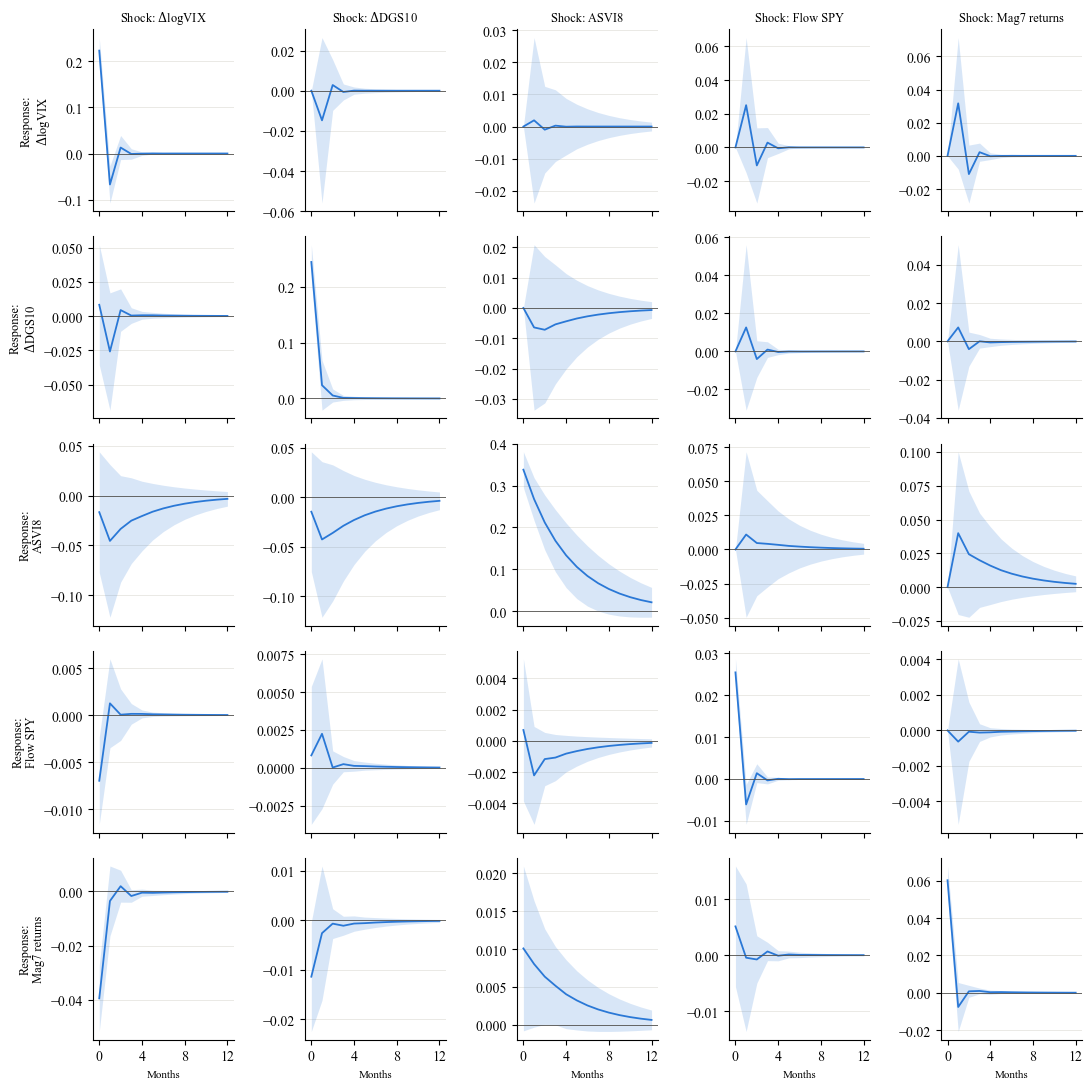

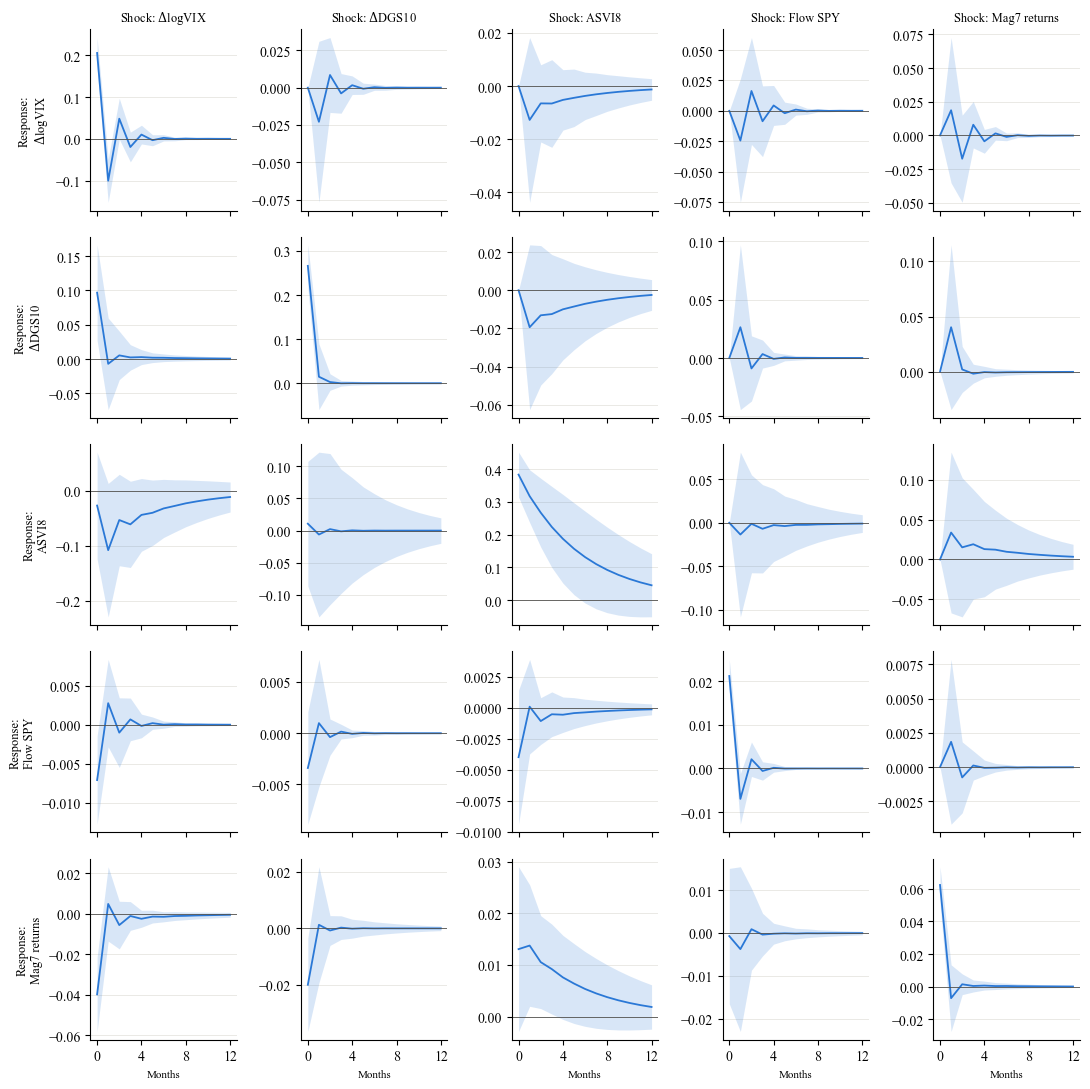

In [28]:
# Figures D.1 and D.2: all 25 impulse responses (rows: responses, columns: shocks)
plot_labels = dict(labels, dlog_vix=r"$\Delta$logVIX", d_dgs10=r"$\Delta$DGS10")
for name, r in res.items():
    irf = r.irf(12)
    point, se = irf.orth_irfs, irf.stderr(orth=True)
    fig, axes = plt.subplots(5, 5, figsize=(11, 11), sharex=True)
    for i in range(5):
        for j in range(5):
            ax = axes[i, j]
            ax.fill_between(range(13), point[:, i, j] - 1.959964 * se[:, i, j],
                            point[:, i, j] + 1.959964 * se[:, i, j], color=blue, alpha=0.18, lw=0)
            ax.plot(range(13), point[:, i, j], color=blue, lw=1.3)
            ax.axhline(0, color=grey, lw=0.6)
            if i == 0:
                ax.set_title("Shock: " + plot_labels[cols[j]], fontsize=9)
            if j == 0:
                ax.set_ylabel("Response:\n" + plot_labels[cols[i]], fontsize=9)
            if i == 4:
                ax.set_xticks([0, 4, 8, 12])
                ax.set_xlabel("Months", fontsize=8)
    plt.tight_layout()
    fig.savefig("output/Figure_D1_IRF_full_sample.png" if name == "Full sample" else "output/Figure_D2_IRF_2021_2025.png",
                dpi=300, bbox_inches="tight")
    plt.show()